# Tugas - Clustering dengan K-Means dan Hierarchical Clustering

| Nama | NRP |
|------|-----|
| Rafa Rizki Aira Swala | 5054251017 |

## Deskripsi Tugas
Pada tugas ini, kalian akan membangun model clustering menggunakan K-Means dan Hierarchical Clustering untuk mengelompokkan posting Facebook penjual berdasarkan pola engagement-nya (like, komentar, share, dan reaksi emoji).

Dataset yang digunakan: `Live.csv` (Facebook Live Sellers in Thailand, UCI). Setiap baris adalah satu posting Facebook dari penjual fashion dan kosmetik di Thailand.

Tujuan utama dari tugas ini adalah memahami cara kerja algoritma clustering secara praktik, khususnya:
1. Penentuan jumlah cluster yang optimal (Elbow Method dan Silhouette Score) serta pengaruh transformasi log dan feature scaling pada K-Means
2. Perbedaan metode linkage dan pembacaan dendrogram pada Hierarchical Clustering
3. Perbandingan hasil K-Means dan Hierarchical Clustering

**Catatan:** Kolom `status_type` TIDAK boleh digunakan sebagai fitur clustering. Kolom ini hanya dipakai untuk membantu menafsirkan cluster pada tahap evaluasi.

Langkah-langkah yang harus dilakukan antara lain:
1. Persiapan Dataset dan Eksplorasi Awal
   - Memuat dataset, melihat struktur data, dan distribusi fitur.
2. Preprocessing
   - Memproses data agar siap digunakan dalam clustering.
3. Eksperimen K-Means
   - Tentukan jumlah cluster dengan Elbow Method dan Silhouette Score, lalu bangun model K-Means.
4. Eksperimen Hierarchical Clustering
   - Amati dendrogram, bandingkan variasi linkage, lalu bangun model Agglomerative Clustering.
5. Evaluasi Model
   - Hitung metrik evaluasi dan visualisasikan hasilnya.
6. Analisis
7. Kesimpulan dan Saran

# 1. Persiapan Dataset dan Eksplorasi Awal

In [1]:
# Cell 1: Import library yang dibutuhkan

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

pd.set_option('display.max_columns', None)
pd.set_option('display.float_format', lambda x: f'{x:,.2f}')
sns.set_style('whitegrid')
plt.rcParams['figure.figsize'] = (10, 6)

RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)

In [2]:
# Cell 2: Load dataset dan tampilkan informasi dasar

df = pd.read_csv('Live.csv')

print("Shape dataset:", df.shape)
print("\n5 baris pertama:")
display(df.head())

print("\nInfo tipe data:")
df.info()

print("\nStatistik deskriptif:")
display(df.describe(include='all'))

print("\nJumlah missing value per kolom:")
display(df.isna().sum().sort_values(ascending=False))

print("\nJumlah baris duplikat:")
print("Duplikat penuh:", df.duplicated().sum())

all_nan_cols = df.columns[df.isna().all()].tolist()
print("\nKolom yang seluruhnya kosong:", all_nan_cols)

Shape dataset: (7050, 16)

5 baris pertama:


,status_id,status_type,status_published,num_reactions,num_comments,num_shares,num_likes,num_loves,num_wows,num_hahas,num_sads,num_angrys,Column1,Column2,Column3,Column4
0,1,video,4/22/2018 6:00,529,512,262,432,92,3,1,1,0,NaN,NaN,NaN,NaN
1,2,photo,4/21/2018 22:45,150,0,0,150,0,0,0,0,0,NaN,NaN,NaN,NaN
2,3,video,4/21/2018 6:17,227,236,57,204,21,1,1,0,0,NaN,NaN,NaN,NaN
3,4,photo,4/21/2018 2:29,111,0,0,111,0,0,0,0,0,NaN,NaN,NaN,NaN
4,5,photo,4/18/2018 3:22,213,0,0,204,9,0,0,0,0,NaN,NaN,NaN,NaN



Info tipe data:
<class 'pandas.DataFrame'>
RangeIndex: 7050 entries, 0 to 7049
Data columns (total 16 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   status_id         7050 non-null   int64  
 1   status_type       7050 non-null   str    
 2   status_published  7050 non-null   str    
 3   num_reactions     7050 non-null   int64  
 4   num_comments      7050 non-null   int64  
 5   num_shares        7050 non-null   int64  
 6   num_likes         7050 non-null   int64  
 7   num_loves         7050 non-null   int64  
 8   num_wows          7050 non-null   int64  
 9   num_hahas         7050 non-null   int64  
 10  num_sads          7050 non-null   int64  
 11  num_angrys        7050 non-null   int64  
 12  Column1           0 non-null      float64
 13  Column2           0 non-null      float64
 14  Column3           0 non-null      float64
 15  Column4           0 non-null      float64
dtypes: float64(4), int64(10), str(2)
mem

,status_id,status_type,status_published,num_reactions,num_comments,num_shares,num_likes,num_loves,num_wows,num_hahas,num_sads,num_angrys,Column1,Column2,Column3,Column4
count,"7,050.00",7050,7050,"7,050.00","7,050.00","7,050.00","7,050.00","7,050.00","7,050.00","7,050.00","7,050.00","7,050.00",0.00,0.00,0.00,0.00
unique,NaN,4,6913,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
top,NaN,photo,3/20/2018 1:54,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
freq,NaN,4288,3,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
mean,"3,525.50",NaN,NaN,230.12,224.36,40.02,215.04,12.73,1.29,0.70,0.24,0.11,NaN,NaN,NaN,NaN
std,"2,035.30",NaN,NaN,462.63,889.64,131.60,449.47,39.97,8.72,3.96,1.60,0.73,NaN,NaN,NaN,NaN
min,1.00,NaN,NaN,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,NaN,NaN,NaN,NaN
25%,"1,763.25",NaN,NaN,17.00,0.00,0.00,17.00,0.00,0.00,0.00,0.00,0.00,NaN,NaN,NaN,NaN
50%,"3,525.50",NaN,NaN,59.50,4.00,0.00,58.00,0.00,0.00,0.00,0.00,0.00,NaN,NaN,NaN,NaN
75%,"5,287.75",NaN,NaN,219.00,23.00,4.00,184.75,3.00,0.00,0.00,0.00,0.00,NaN,NaN,NaN,NaN



Jumlah missing value per kolom:


Column1             7050
Column2             7050
Column3             7050
Column4             7050
status_id              0
status_type            0
status_published       0
num_reactions          0
num_loves              0
num_likes              0
num_shares             0
num_comments           0
num_angrys             0
num_sads               0
num_hahas              0
num_wows               0
dtype: int64


Jumlah baris duplikat:
Duplikat penuh: 0

Kolom yang seluruhnya kosong: ['Column1', 'Column2', 'Column3', 'Column4']


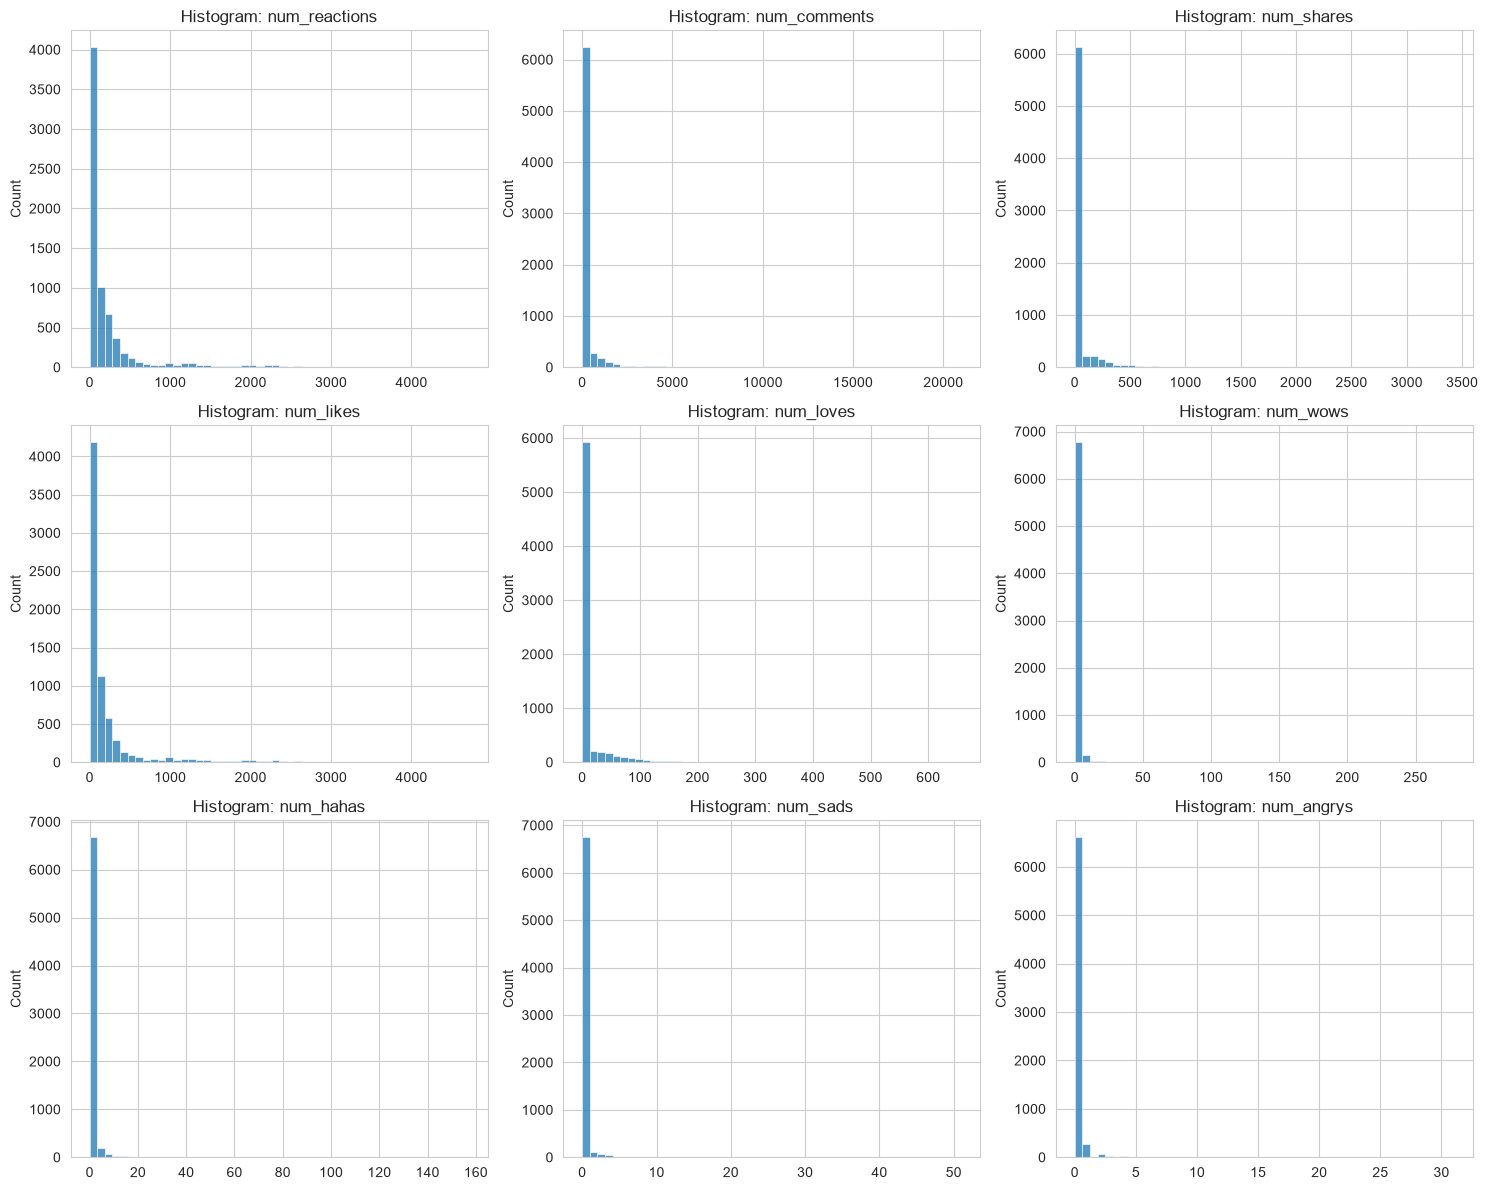

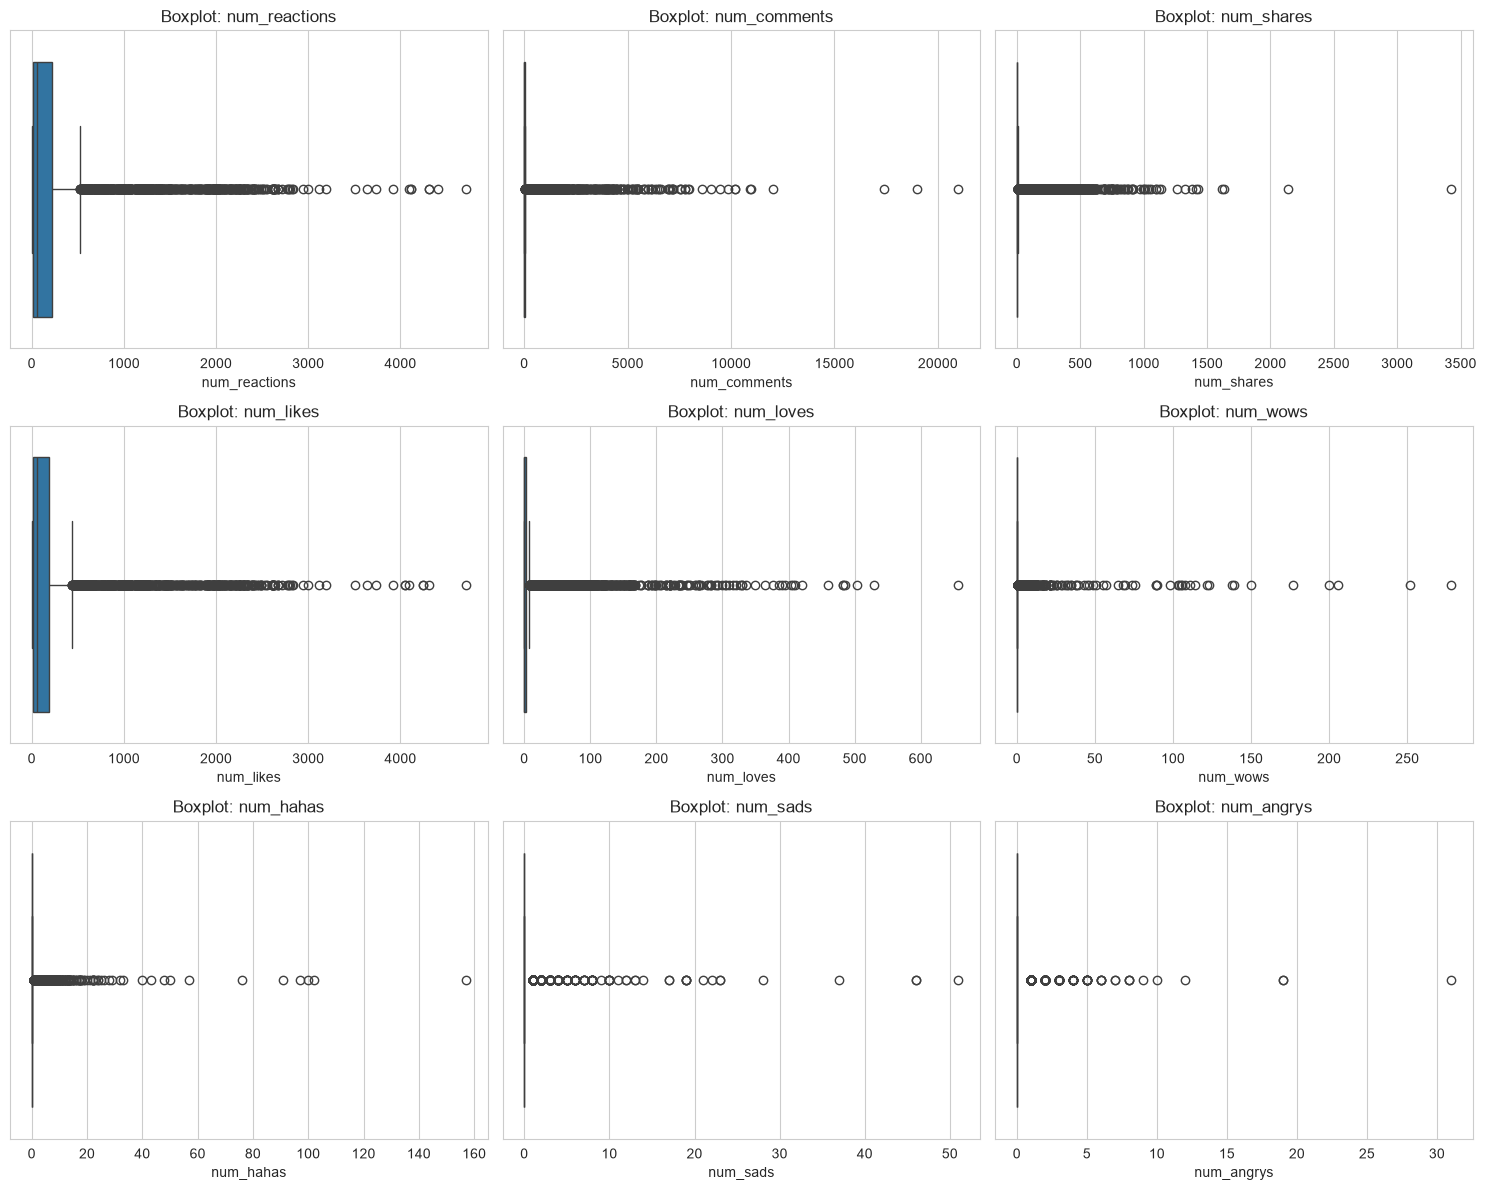


Skewness, proporsi nol, max, mean:


,skewness,proporsi_nol,max,mean
num_hahas,20.31,0.84,157,0.70
num_angrys,19.51,0.94,31,0.11
num_wows,18.25,0.75,278,1.29
num_sads,17.58,0.91,51,0.24
num_comments,9.03,0.30,20990,224.36
num_shares,7.10,0.55,3424,40.02
num_loves,6.00,0.60,657,12.73
num_likes,3.92,0.02,4710,215.04
num_reactions,3.74,0.02,4710,230.12


In [3]:
# Cell 3: Distribusi fitur hitungan (histogram & boxplot)

count_cols = ['num_reactions', 'num_comments', 'num_shares',
              'num_likes', 'num_loves', 'num_wows',
              'num_hahas', 'num_sads', 'num_angrys']

fig, axes = plt.subplots(3, 3, figsize=(15, 12))
axes = axes.flatten()
for i, col in enumerate(count_cols):
    sns.histplot(df[col], bins=50, ax=axes[i], kde=False)
    axes[i].set_title(f'Histogram: {col}')
    axes[i].set_xlabel('')
plt.tight_layout()
plt.show()

fig, axes = plt.subplots(3, 3, figsize=(15, 12))
axes = axes.flatten()
for i, col in enumerate(count_cols):
    sns.boxplot(x=df[col], ax=axes[i])
    axes[i].set_title(f'Boxplot: {col}')
plt.tight_layout()
plt.show()

summary = pd.DataFrame({
    'skewness': df[count_cols].skew(),
    'proporsi_nol': (df[count_cols] == 0).mean(),
    'max': df[count_cols].max(),
    'mean': df[count_cols].mean()
}).sort_values('skewness', ascending=False)
print("\nSkewness, proporsi nol, max, mean:")
display(summary)

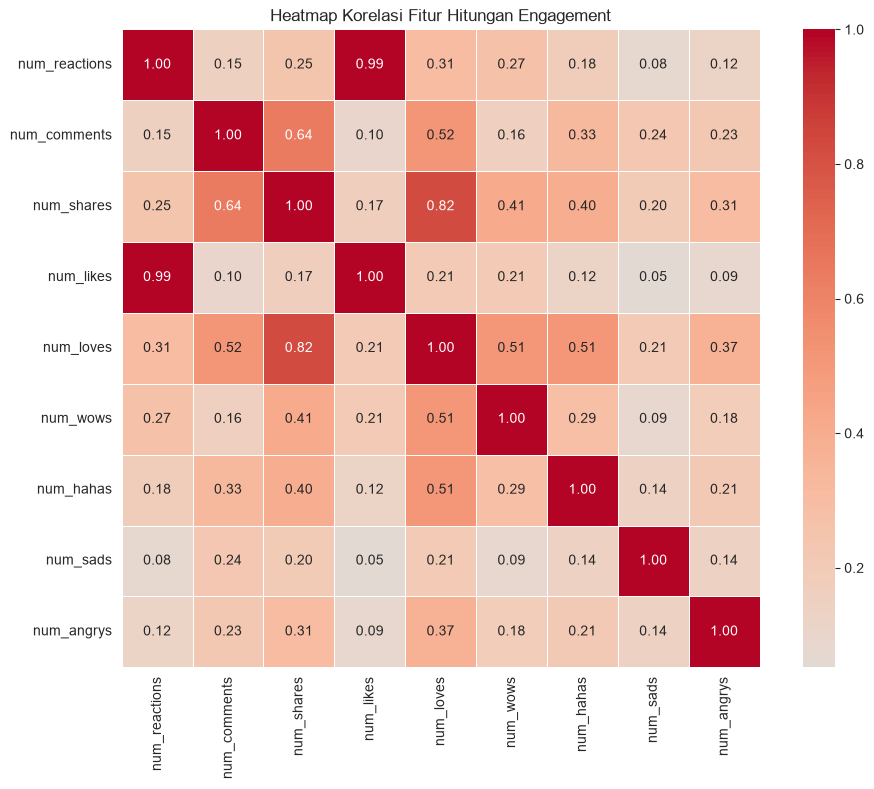


Pasangan fitur dengan korelasi sangat tinggi (|r| > 0.9):


num_reactions  num_likes   0.99
dtype: float64

In [4]:
# Cell 4: Heatmap korelasi antar fitur hitungan

corr_matrix = df[count_cols].corr()

plt.figure(figsize=(10, 8))
sns.heatmap(corr_matrix, annot=True, fmt='.2f', cmap='coolwarm',
            center=0, square=True, linewidths=0.5)
plt.title('Heatmap Korelasi Fitur Hitungan Engagement')
plt.tight_layout()
plt.show()

corr_pairs = (corr_matrix.where(np.triu(np.ones(corr_matrix.shape), k=1).astype(bool))
                          .stack()
                          .sort_values(ascending=False))
print("\nPasangan fitur dengan korelasi sangat tinggi (|r| > 0.9):")
display(corr_pairs[corr_pairs.abs() > 0.9])

Rentang waktu: 2012-07-15 02:51:00 s.d. 2018-06-13 01:12:00
Jumlah NaT: 0

Jumlah posting & proporsi posting dengan reaksi emoji per tahun:


,jumlah_posting,proporsi_punya_emoji
year,,
2012,589,0.00
2013,500,0.00
2014,233,0.00
2015,337,0.00
2016,588,0.68
2017,2253,0.54
2018,2550,0.58


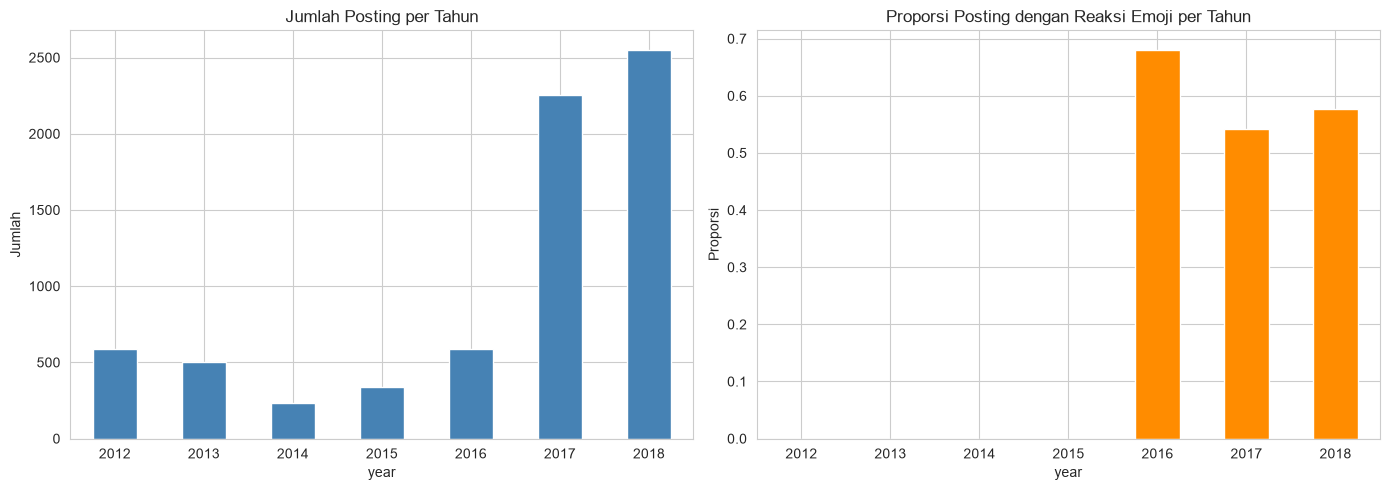

In [5]:
# Cell 5: Konversi status_published ke datetime & pola per tahun

df['status_published'] = pd.to_datetime(df['status_published'], errors='coerce')

print("Rentang waktu:", df['status_published'].min(), "s.d.", df['status_published'].max())
print("Jumlah NaT:", df['status_published'].isna().sum())

df['year'] = df['status_published'].dt.year

posting_per_year = df['year'].value_counts().sort_index()

emoji_cols = ['num_loves', 'num_wows', 'num_hahas', 'num_sads', 'num_angrys']
df['has_emoji_reaction'] = (df[emoji_cols].sum(axis=1) > 0)

prop_emoji_per_year = df.groupby('year')['has_emoji_reaction'].mean()

tahun_summary = pd.DataFrame({
    'jumlah_posting': posting_per_year,
    'proporsi_punya_emoji': prop_emoji_per_year
})
print("\nJumlah posting & proporsi posting dengan reaksi emoji per tahun:")
display(tahun_summary)

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
posting_per_year.plot(kind='bar', ax=axes[0], color='steelblue')
axes[0].set_title('Jumlah Posting per Tahun')
axes[0].set_ylabel('Jumlah')
axes[0].tick_params(axis='x', rotation=0)

prop_emoji_per_year.plot(kind='bar', ax=axes[1], color='darkorange')
axes[1].set_title('Proporsi Posting dengan Reaksi Emoji per Tahun')
axes[1].set_ylabel('Proporsi')
axes[1].tick_params(axis='x', rotation=0)
plt.tight_layout()
plt.show()

C:\Users\airal\AppData\Local\Temp\ipykernel_33788\4096872927.py:4: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(data=df, x='status_type', order=df['status_type'].value_counts().index,


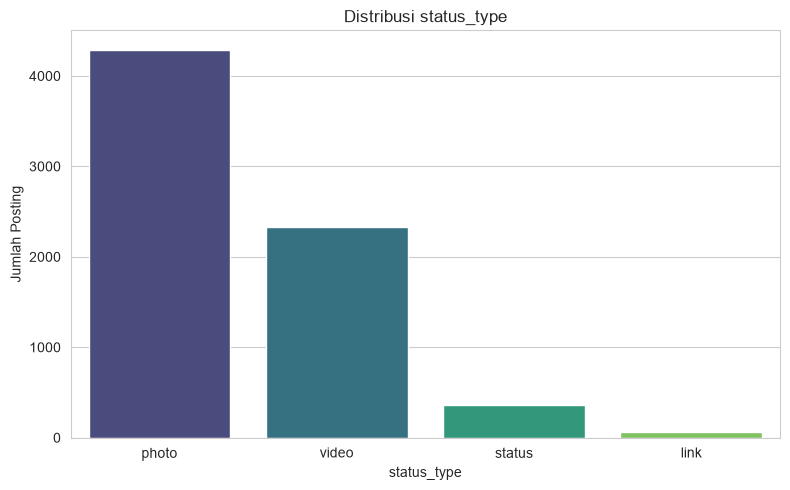


Median num_likes, num_comments, num_shares per status_type:


,num_likes,num_comments,num_shares
status_type,,,
link,48.00,1.00,0.00
photo,34.00,2.00,0.00
status,117.00,10.00,0.00
video,117.00,39.00,12.00


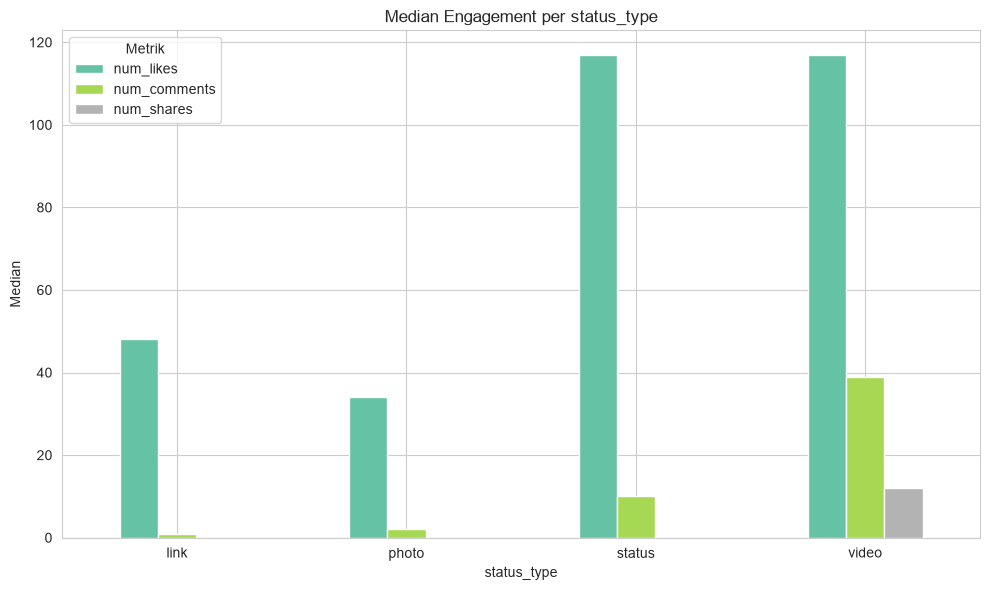

In [6]:
# Cell 6: Distribusi status_type & median engagement per status_type

plt.figure(figsize=(8, 5))
sns.countplot(data=df, x='status_type', order=df['status_type'].value_counts().index,
              palette='viridis')
plt.title('Distribusi status_type')
plt.xlabel('status_type')
plt.ylabel('Jumlah Posting')
plt.tight_layout()
plt.show()

median_by_status = df.groupby('status_type')[['num_likes', 'num_comments', 'num_shares']].median()
print("\nMedian num_likes, num_comments, num_shares per status_type:")
display(median_by_status)

median_by_status.plot(kind='bar', figsize=(10, 6), colormap='Set2')
plt.title('Median Engagement per status_type')
plt.ylabel('Median')
plt.xlabel('status_type')
plt.xticks(rotation=0)
plt.legend(title='Metrik')
plt.tight_layout()
plt.show()

## Lakukan Exploratory Data Analysis (EDA) tambahan yang diperlukan.

# 2. Preprocessing

In [7]:
# Cell 1: Hapus kolom kosong, tangani duplikat, cek missing value & outlier

# 1) Hapus kolom yang seluruhnya kosong
all_nan_cols = df.columns[df.isna().all()].tolist()
print("Kolom yang dihapus (seluruhnya kosong):", all_nan_cols)
df = df.drop(columns=all_nan_cols)

# 2) Duplikat
# status_id unik per baris -> duplikat dicek tanpa status_id
print("\nJumlah baris sebelum hapus duplikat:", len(df))
duplicated_mask = df.drop(columns=['status_id']).duplicated(keep='first')
print("Jumlah baris duplikat (tanpa status_id):", duplicated_mask.sum())
df = df[~duplicated_mask].reset_index(drop=True)
print("Jumlah baris setelah hapus duplikat:", len(df))

# 3) Missing value
print("\nMissing value setelah drop kolom kosong & duplikat:")
mv = df.isna().sum().sort_values(ascending=False)
display(mv[mv > 0] if (mv > 0).any() else "Tidak ada missing value.")

# 4) Outlier ekstrem
count_cols = ['num_reactions', 'num_comments', 'num_shares',
              'num_likes', 'num_loves', 'num_wows',
              'num_hahas', 'num_sads', 'num_angrys']

print("\nNilai maksimum tiap fitur hitungan:")
print(df[count_cols].max())

# Cek outlier ekstrem pakai IQR (hanya untuk laporan, tidak dihapus)
Q1 = df[count_cols].quantile(0.25)
Q3 = df[count_cols].quantile(0.75)
IQR = Q3 - Q1
outlier_frac = ((df[count_cols] > Q3 + 1.5 * IQR) | (df[count_cols] < Q1 - 1.5 * IQR)).mean()
print("\nProporsi outlier (IQR) per fitur:")
display(outlier_frac.sort_values(ascending=False).to_frame('proporsi_outlier'))

# Keputusan: outlier TIDAK dihapus karena
# (a) nilai ekstrem (posting viral) adalah informasi nyata engagement,
# (b) akan diredam oleh log1p + StandardScaler.

Kolom yang dihapus (seluruhnya kosong): ['Column1', 'Column2', 'Column3', 'Column4']

Jumlah baris sebelum hapus duplikat: 7050
Jumlah baris duplikat (tanpa status_id): 54
Jumlah baris setelah hapus duplikat: 6996

Missing value setelah drop kolom kosong & duplikat:


'Tidak ada missing value.'


Nilai maksimum tiap fitur hitungan:
num_reactions     4710
num_comments     20990
num_shares        3424
num_likes         4710
num_loves          657
num_wows           278
num_hahas          157
num_sads            51
num_angrys          31
dtype: int64

Proporsi outlier (IQR) per fitur:


,proporsi_outlier
num_wows,0.24
num_shares,0.20
num_comments,0.20
num_loves,0.19
num_hahas,0.16
num_likes,0.11
num_reactions,0.10
num_sads,0.09
num_angrys,0.06


In [8]:
# Cell 2: Pisahkan kolom interpretasi, hapus kolom tidak relevan, pilih fitur

# Kolom untuk interpretasi cluster (TIDAK dipakai clustering)
meta_cols = ['status_id', 'status_type', 'status_published']
meta_df = df[meta_cols].copy()

# Cek redundansi: num_reactions = jumlah semua reaksi emoji?
reaction_parts = ['num_likes', 'num_loves', 'num_wows', 'num_hahas', 'num_sads', 'num_angrys']
redundan_check = (df[reaction_parts].sum(axis=1) - df['num_reactions']).abs()
print("Selisih (sum reaksi - num_reactions): max =", redundan_check.max())
print("Korelasi num_reactions vs num_likes:",
      df['num_reactions'].corr(df['num_likes']).round(4))

# Cek fitur yang sebagian besar nol
count_cols = ['num_reactions', 'num_comments', 'num_shares',
              'num_likes', 'num_loves', 'num_wows',
              'num_hahas', 'num_sads', 'num_angrys']
zero_frac = (df[count_cols] == 0).mean().sort_values(ascending=False)
print("\nProporsi nol per fitur:")
display(zero_frac.to_frame('proporsi_nol'))

# Keputusan fitur:
# - num_reactions di-DROP karena redundan (= jumlah suku emoji), dan sangat
#   berkorelasi dengan num_likes -> mendominasi jarak.
# - Emoji sparse (wows, hahas, sads, angrys) DIGABUNG jadi satu fitur
#   num_other_reactions karena mayoritas nol & maknanya mirip (reaksi non-like/love).
df['num_other_reactions'] = df[['num_wows', 'num_hahas', 'num_sads', 'num_angrys']].sum(axis=1)

features = ['num_likes', 'num_loves', 'num_other_reactions',
            'num_comments', 'num_shares']

print("\nFitur final untuk clustering:", features)
display(df[features].describe())

Selisih (sum reaksi - num_reactions): max = 4
Korelasi num_reactions vs num_likes: 0.9947

Proporsi nol per fitur:


,proporsi_nol
num_angrys,0.94
num_sads,0.91
num_hahas,0.84
num_wows,0.76
num_loves,0.60
num_shares,0.56
num_comments,0.30
num_likes,0.02
num_reactions,0.02



Fitur final untuk clustering: ['num_likes', 'num_loves', 'num_other_reactions', 'num_comments', 'num_shares']


,num_likes,num_loves,num_other_reactions,num_comments,num_shares
count,"6,996.00","6,996.00","6,996.00","6,996.00","6,996.00"
mean,210.04,12.76,2.29,225.65,40.28
std,439.62,40.11,11.07,892.92,132.07
min,0.00,0.00,0.00,0.00,0.00
25%,17.00,0.00,0.00,0.00,0.00
50%,57.00,0.00,0.00,4.00,0.00
75%,182.00,3.00,1.00,22.25,4.00
max,"4,710.00",657.00,286.00,"20,990.00","3,424.00"


**Fitur yang dipilih untuk clustering:** num_likes, num_loves, num_other_reactions, num_comments, num_shares

Alasan:

num_reactions dihapus karena merupakan penjumlahan dari fitur emoji (redundan) dan sangat berkorelasi dengan num_likes, sehingga akan mendominasi perhitungan jarak.

num_wows, num_hahas, num_sads, num_angrys digabung menjadi num_other_reactions karena mayoritas bernilai nol (sparse) dan maknanya serupa (reaksi non-like/love); penggabungan mengurangi noise dan dimensi.

num_likes, num_loves, num_comments, num_shares dipertahankan karena mewakili empat sinyal engagement utama yang berbeda (apresiasi pasif, apresiasi aktif, diskusi, penyebaran).

status_id, status_type, status_published disisihkan sebagai metadata untuk interpretasi cluster, bukan fitur clustering.

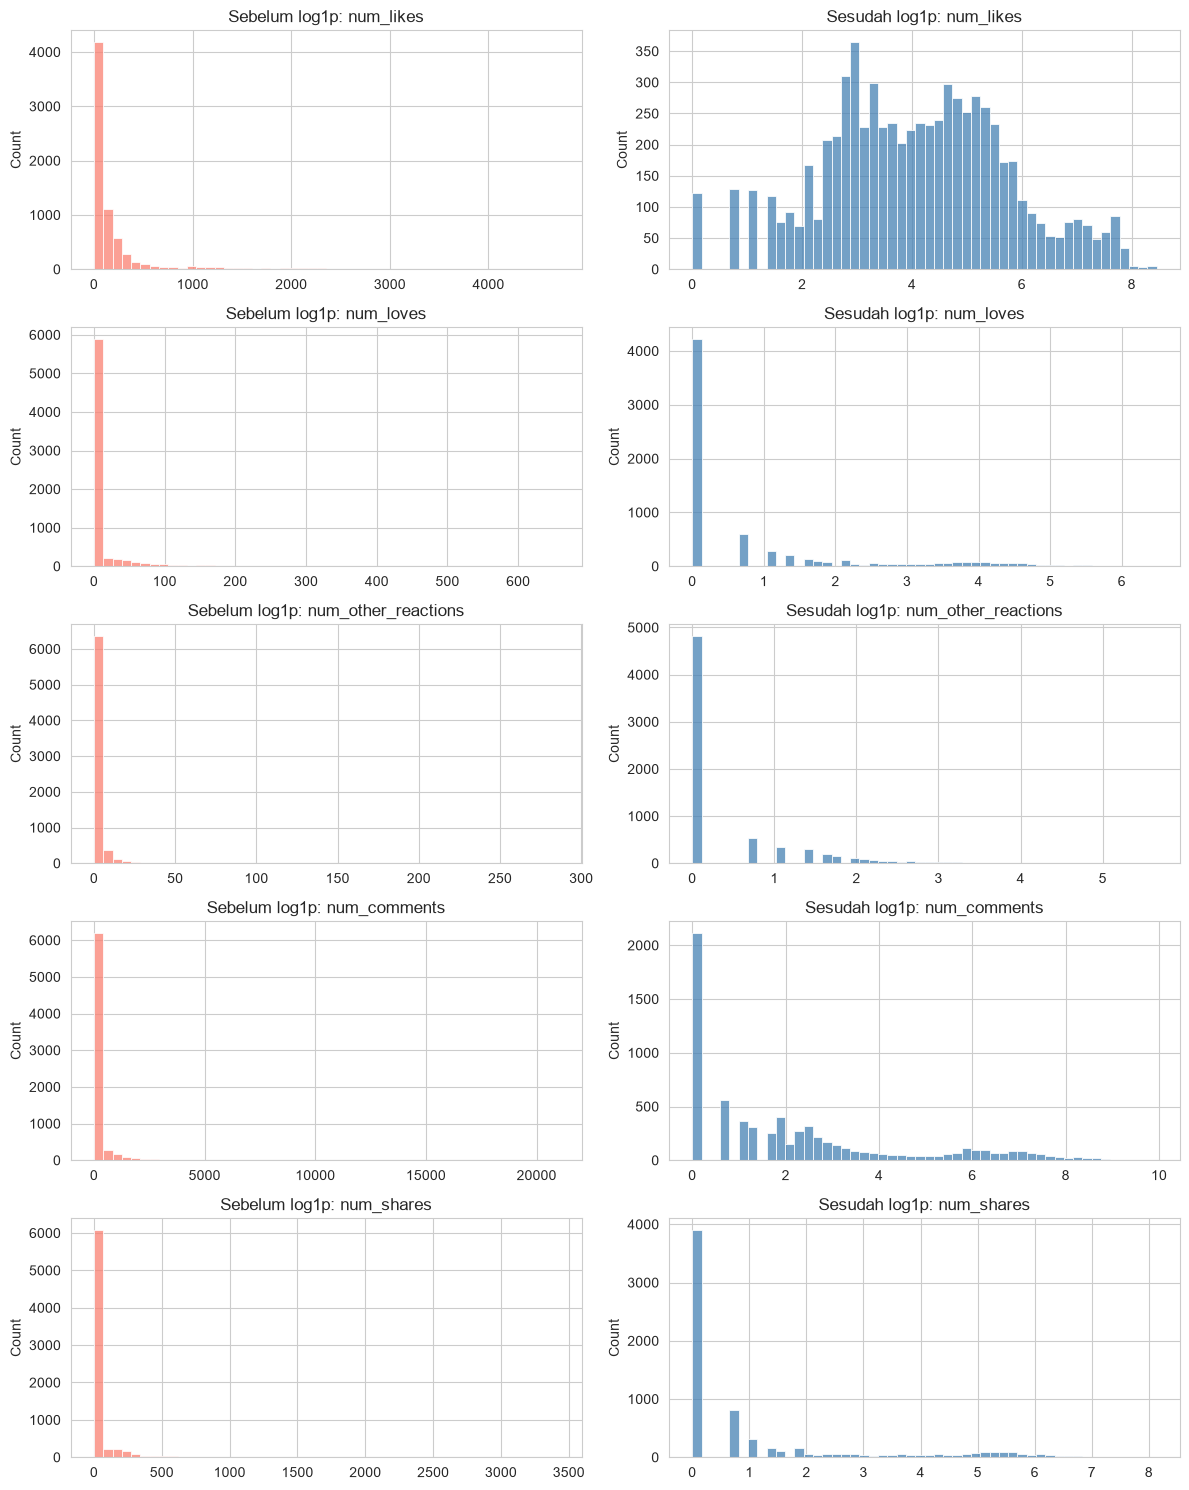

Perbandingan skewness sebelum vs sesudah log1p:


,skew_sebelum,skew_sesudah
num_likes,3.93,-0.01
num_loves,5.99,1.52
num_other_reactions,13.99,1.98
num_comments,8.99,1.05
num_shares,7.07,1.53


In [9]:
# Cell 3: Terapkan log1p pada fitur terpilih, bandingkan distribusi

X_log = df[features].copy()
X_log = np.log1p(X_log)

fig, axes = plt.subplots(len(features), 2, figsize=(12, 3 * len(features)))
for i, col in enumerate(features):
    sns.histplot(df[col], bins=50, ax=axes[i, 0], color='salmon')
    axes[i, 0].set_title(f'Sebelum log1p: {col}')
    axes[i, 0].set_xlabel('')

    sns.histplot(X_log[col], bins=50, ax=axes[i, 1], color='steelblue')
    axes[i, 1].set_title(f'Sesudah log1p: {col}')
    axes[i, 1].set_xlabel('')
plt.tight_layout()
plt.show()

compare = pd.DataFrame({
    'skew_sebelum': df[features].skew(),
    'skew_sesudah': X_log.skew()
})
print("Perbandingan skewness sebelum vs sesudah log1p:")
display(compare)

In [10]:
# Cell 4: StandardScaler pada data log, plus varian mentah untuk perbandingan

from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()

# Fitur hasil log1p + scaling
X_log_scaled = pd.DataFrame(
    scaler.fit_transform(X_log),
    columns=features
)

# Varian mentah (tanpa transformasi, tanpa scaling)
X_raw = df[features].copy()

# Varian mentah + scaling saja
X_raw_scaled = pd.DataFrame(
    StandardScaler().fit_transform(X_raw),
    columns=features
)

print("Shape X_log_scaled:", X_log_scaled.shape)
print("Shape X_raw:", X_raw.shape)
print("Shape X_raw_scaled:", X_raw_scaled.shape)

print("\nStatistik X_log_scaled (mean ~0, std ~1):")
display(X_log_scaled.describe().loc[['mean', 'std']])

print("\n5 baris pertama X_log_scaled:")
display(X_log_scaled.head())

Shape X_log_scaled: (6996, 5)
Shape X_raw: (6996, 5)
Shape X_raw_scaled: (6996, 5)

Statistik X_log_scaled (mean ~0, std ~1):


,num_likes,num_loves,num_other_reactions,num_comments,num_shares
mean,-0.00,-0.00,-0.00,-0.00,0.00
std,1.00,1.00,1.00,1.00,1.00



5 baris pertama X_log_scaled:


,num_likes,num_loves,num_other_reactions,num_comments,num_shares
0,1.20,2.39,1.50,1.72,2.31
1,0.58,-0.63,-0.56,-0.95,-0.64
2,0.76,1.43,0.70,1.39,1.51
3,0.40,-0.63,-0.56,-0.95,-0.64
4,0.76,0.91,-0.56,-0.95,-0.64


# 3. Eksperimen K-Means

## 3.1 Pengaruh Transformasi Log dan Feature Scaling pada K-Means

K-Means mengelompokkan data dengan meminimalkan jarak antara titik dan centroid cluster. Pada bagian ini kalian akan mengamati bagaimana transformasi log dan scaling memengaruhi hasil clustering.

In [11]:
# Cell 1 (3.1): Latih K-Means k=3 pada X_raw, X_raw_scaled, X_log_scaled

from sklearn.cluster import KMeans

K_COMPARE = 3

models_31 = {}
labels_31 = {}

for name, X in [('X_raw', X_raw),
                ('X_raw_scaled', X_raw_scaled),
                ('X_log_scaled', X_log_scaled)]:
    km = KMeans(n_clusters=K_COMPARE, random_state=RANDOM_STATE, n_init=10)
    lab = km.fit_predict(X)
    models_31[name] = km
    labels_31[name] = lab

print("Model K-Means k=3 selesai dilatih pada tiga versi data.")

Model K-Means k=3 selesai dilatih pada tiga versi data.


,versi_data,ukuran_cluster,min_size,max_size,silhouette_di_X_log_scaled,silhouette_di_ruang_sendiri
0,X_raw,"[6392, 137, 467]",137,6392,0.30,0.79
1,X_raw_scaled,"[292, 6331, 373]",292,6331,0.24,0.76
2,X_log_scaled,"[2200, 3647, 1149]",1149,3647,0.43,0.43



Varians fitur pada X_raw (tanpa scaling):


,varians
num_comments,"797,310.07"
num_likes,"193,268.44"
num_shares,"17,443.17"
num_loves,"1,609.18"
num_other_reactions,122.61



Rasio varians terbesar/terkecil pada X_raw: 6502.63


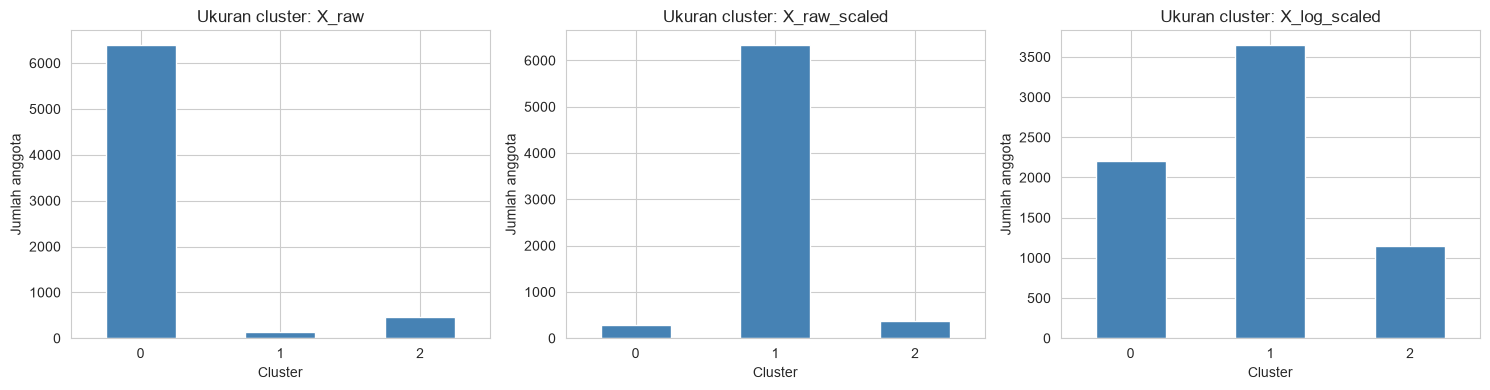

In [12]:
# Cell 2 (3.1): Bandingkan jumlah anggota & silhouette di ruang X_log_scaled

from sklearn.metrics import silhouette_score

# Silhouette dihitung pada ruang yang SAMA (X_log_scaled) untuk perbandingan adil
hasil_31 = []
for name, lab in labels_31.items():
    sizes = pd.Series(lab).value_counts().sort_index()
    sil_same_space = silhouette_score(X_log_scaled, lab)
    sil_own_space = silhouette_score(
        {'X_raw': X_raw, 'X_raw_scaled': X_raw_scaled, 'X_log_scaled': X_log_scaled}[name],
        lab
    )
    hasil_31.append({
        'versi_data': name,
        'ukuran_cluster': sizes.tolist(),
        'min_size': sizes.min(),
        'max_size': sizes.max(),
        'silhouette_di_X_log_scaled': round(sil_same_space, 4),
        'silhouette_di_ruang_sendiri': round(sil_own_space, 4)
    })

df_hasil_31 = pd.DataFrame(hasil_31)
display(df_hasil_31)

# Fitur mana yang mendominasi varians pada data TANPA scaling?
var_raw = X_raw.var().sort_values(ascending=False)
print("\nVarians fitur pada X_raw (tanpa scaling):")
display(var_raw.to_frame('varians'))

print("\nRasio varians terbesar/terkecil pada X_raw:",
      round(var_raw.max() / var_raw.min(), 2))

# Visualisasi proporsi ukuran cluster
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, (name, lab) in zip(axes, labels_31.items()):
    pd.Series(lab).value_counts().sort_index().plot(
        kind='bar', ax=ax, color='steelblue'
    )
    ax.set_title(f'Ukuran cluster: {name}')
    ax.set_xlabel('Cluster')
    ax.set_ylabel('Jumlah anggota')
    ax.tick_params(axis='x', rotation=0)
plt.tight_layout()
plt.show()

## 3.2 Menentukan Jumlah Cluster dengan Elbow Method

Elbow Method memplot nilai inertia (Within-Cluster Sum of Squares) terhadap jumlah cluster k. Titik "siku" pada grafik menunjukkan nilai k setelah mana penambahan cluster tidak lagi memberikan penurunan inertia yang berarti.

In [13]:
# Cell 1 (3.2): Hitung inertia untuk k = 2..10 pada X_log_scaled

K_RANGE = range(2, 11)
inertias = []

for k in K_RANGE:
    km = KMeans(n_clusters=k, random_state=RANDOM_STATE, n_init=10)
    km.fit(X_log_scaled)
    inertias.append(km.inertia_)

df_elbow = pd.DataFrame({'k': list(K_RANGE), 'inertia': inertias})
display(df_elbow)

,k,inertia
0,2,"15,075.91"
1,3,"10,144.12"
2,4,"8,448.68"
3,5,"7,360.90"
4,6,"6,348.50"
5,7,"5,737.20"
6,8,"5,306.32"
7,9,"4,878.49"
8,10,"4,584.49"


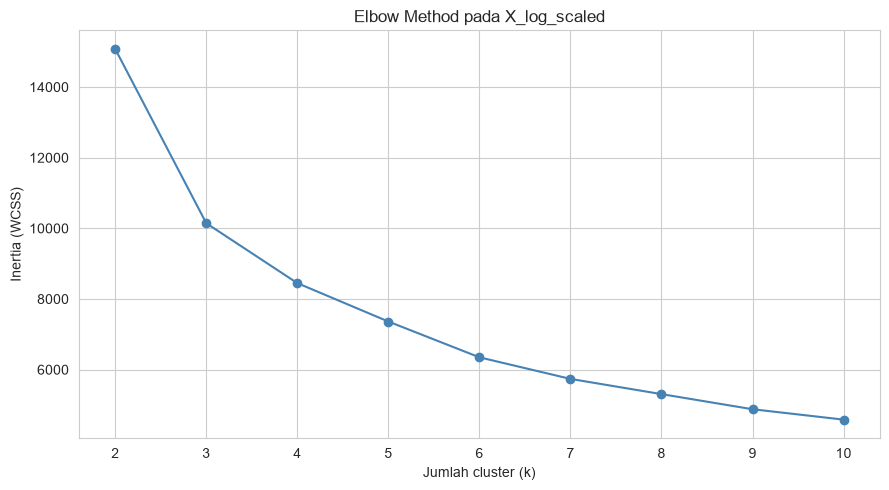

Library 'kneed' tidak terpasang. Deteksi elbow dilakukan manual dari grafik.


In [14]:
# Cell 2 (3.2): Plot Elbow + deteksi otomatis dengan KneeLocator (opsional)

plt.figure(figsize=(9, 5))
plt.plot(df_elbow['k'], df_elbow['inertia'], marker='o', color='steelblue')
plt.title('Elbow Method pada X_log_scaled')
plt.xlabel('Jumlah cluster (k)')
plt.ylabel('Inertia (WCSS)')
plt.xticks(df_elbow['k'])
plt.grid(True)
plt.tight_layout()
plt.show()

try:
    from kneed import KneeLocator
    kl = KneeLocator(df_elbow['k'], df_elbow['inertia'],
                     curve='convex', direction='decreasing')
    print("Elbow terdeteksi otomatis pada k =", kl.elbow)
except ImportError:
    print("Library 'kneed' tidak terpasang. Deteksi elbow dilakukan manual dari grafik.")

## 3.3 Menentukan Jumlah Cluster dengan Silhouette Score

Silhouette Score mengukur seberapa mirip sebuah titik dengan clusternya sendiri dibandingkan dengan cluster lain. Nilainya berkisar dari -1 sampai 1, semakin tinggi semakin baik.

In [15]:
# Cell 1 (3.3): Hitung silhouette score untuk k = 2..10 pada X_log_scaled

from sklearn.metrics import silhouette_score

sil_scores = {}

for k in K_RANGE:
    km = KMeans(n_clusters=k, random_state=RANDOM_STATE, n_init=10)
    lab = km.fit_predict(X_log_scaled)
    sil_scores[k] = silhouette_score(X_log_scaled, lab)

df_sil = pd.DataFrame({'k': list(sil_scores.keys()),
                       'silhouette': list(sil_scores.values())})
display(df_sil)

k_best_sil = df_sil.loc[df_sil['silhouette'].idxmax(), 'k']
print("k dengan silhouette tertinggi:", k_best_sil,
      "->", round(df_sil['silhouette'].max(), 4))

,k,silhouette
0,2,0.59
1,3,0.43
2,4,0.41
3,5,0.40
4,6,0.30
5,7,0.31
6,8,0.30
7,9,0.30
8,10,0.30


k dengan silhouette tertinggi: 2 -> 0.5871


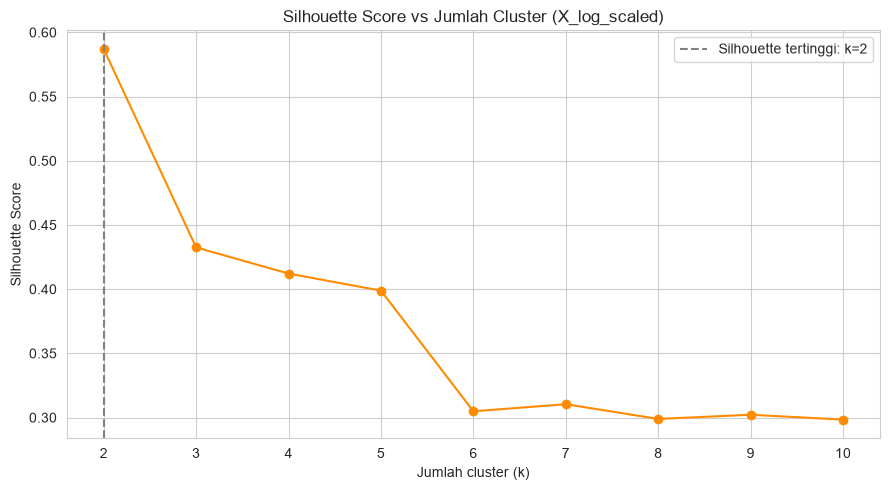

In [16]:
# Cell 2 (3.3): Plot silhouette score terhadap k

plt.figure(figsize=(9, 5))
plt.plot(df_sil['k'], df_sil['silhouette'], marker='o', color='darkorange')
plt.axvline(k_best_sil, color='gray', linestyle='--',
            label=f'Silhouette tertinggi: k={k_best_sil}')
plt.title('Silhouette Score vs Jumlah Cluster (X_log_scaled)')
plt.xlabel('Jumlah cluster (k)')
plt.ylabel('Silhouette Score')
plt.xticks(df_sil['k'])
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()

**Pilihan k untuk K-Means:** k = 3

Alasan singkat: Silhouette Score mencapai puncaknya pada k = 3, dan grafik Elbow juga menunjukkan penurunan inertia yang mulai melandai di sekitar k = 3–4 (tikungan paling terlihat di k = 3)

## 3.4 Model K-Means Final

In [17]:
# Cell 1 (3.4): Latih model final dengan k terpilih

K_FINAL = 3

km_final = KMeans(n_clusters=K_FINAL, random_state=RANDOM_STATE, n_init=10)
labels_km = km_final.fit_predict(X_log_scaled)

df['cluster_km'] = labels_km

sil_final = silhouette_score(X_log_scaled, labels_km)
print("K-Means final dilatih dengan k =", K_FINAL)
print("Inertia:", round(km_final.inertia_, 4))
print("Silhouette Score:", round(sil_final, 4))
print("\nJumlah anggota per cluster:")
print(pd.Series(labels_km).value_counts().sort_index())

K-Means final dilatih dengan k = 3
Inertia: 10144.1205
Silhouette Score: 0.4325

Jumlah anggota per cluster:
0    2200
1    3647
2    1149
Name: count, dtype: int64


Profil cluster (MEDIAN) pada data asli:


,num_likes,num_loves,num_other_reactions,num_comments,num_shares,jumlah_anggota
cluster_km,,,,,,
0,204.50,1.00,0.00,11.00,1.00,2200
1,18.00,0.00,0.00,0.00,0.00,3647
2,177.00,51.00,4.00,703.00,174.00,1149



Profil cluster (MEAN) pada data asli:


,num_likes,num_loves,num_other_reactions,num_comments,num_shares
cluster_km,,,,,
0,458.46,2.62,1.57,28.02,5.03
1,23.00,0.14,0.06,2.22,0.55
2,328.04,72.19,10.75,"1,313.25",233.87


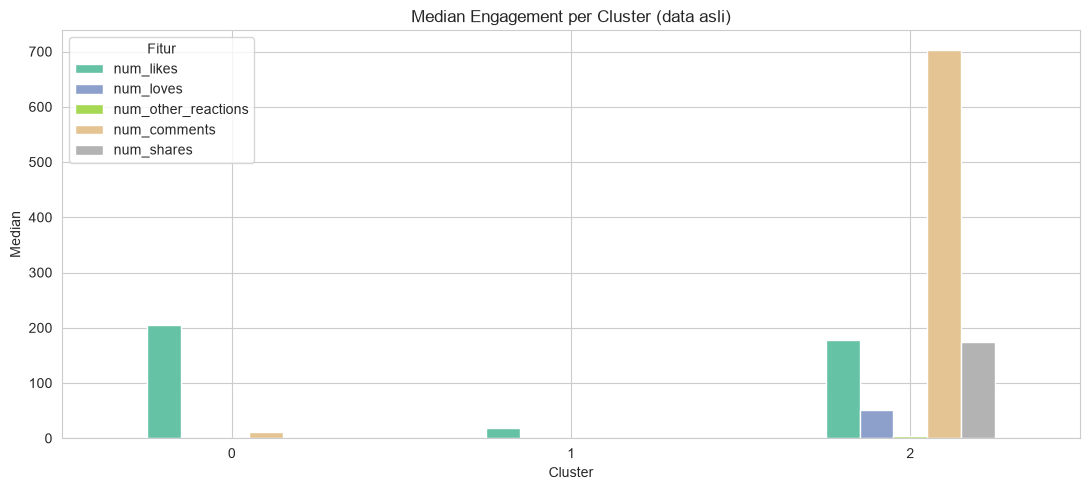

In [18]:
# Cell 2 (3.4): Profil cluster pada data asli (median & mean) + jumlah anggota

fitur_profil = ['num_likes', 'num_loves', 'num_other_reactions',
                'num_comments', 'num_shares']

# Median per cluster
profil_median = df.groupby('cluster_km')[fitur_profil].median()
profil_median['jumlah_anggota'] = df.groupby('cluster_km').size()

# Mean per cluster
profil_mean = df.groupby('cluster_km')[fitur_profil].mean()

print("Profil cluster (MEDIAN) pada data asli:")
display(profil_median)

print("\nProfil cluster (MEAN) pada data asli:")
display(profil_mean)

# Visualisasi median per cluster
profil_median[fitur_profil].plot(
    kind='bar', figsize=(11, 5), colormap='Set2'
)
plt.title('Median Engagement per Cluster (data asli)')
plt.xlabel('Cluster')
plt.ylabel('Median')
plt.xticks(rotation=0)
plt.legend(title='Fitur')
plt.tight_layout()
plt.show()

# 4. Eksperimen Hierarchical Clustering

## 4.1 Dendrogram

Hierarchical Clustering (Agglomerative) memulai dengan setiap titik sebagai cluster tersendiri, lalu menggabungkan dua cluster terdekat secara berulang hingga tersisa satu cluster. Dendrogram memvisualisasikan proses penggabungan tersebut.

In [19]:
# Cell 1 (4.1): Hitung linkage matrix dengan metode ward pada X_log_scaled

from scipy.cluster.hierarchy import linkage

Z_ward = linkage(X_log_scaled, method='ward')
print("Shape linkage matrix:", Z_ward.shape)
print("5 baris pertama linkage matrix:")
display(pd.DataFrame(Z_ward[:5],
                     columns=['cluster_a', 'cluster_b',
                              'jarak', 'jumlah_anggota']))

Shape linkage matrix: (6995, 4)
5 baris pertama linkage matrix:


,cluster_a,cluster_b,jarak,jumlah_anggota
0,23.00,"1,711.00",0.00,2.00
1,"3,637.00","6,309.00",0.00,2.00
2,70.00,"5,021.00",0.00,2.00
3,75.00,"1,814.00",0.00,2.00
4,79.00,"1,592.00",0.00,2.00


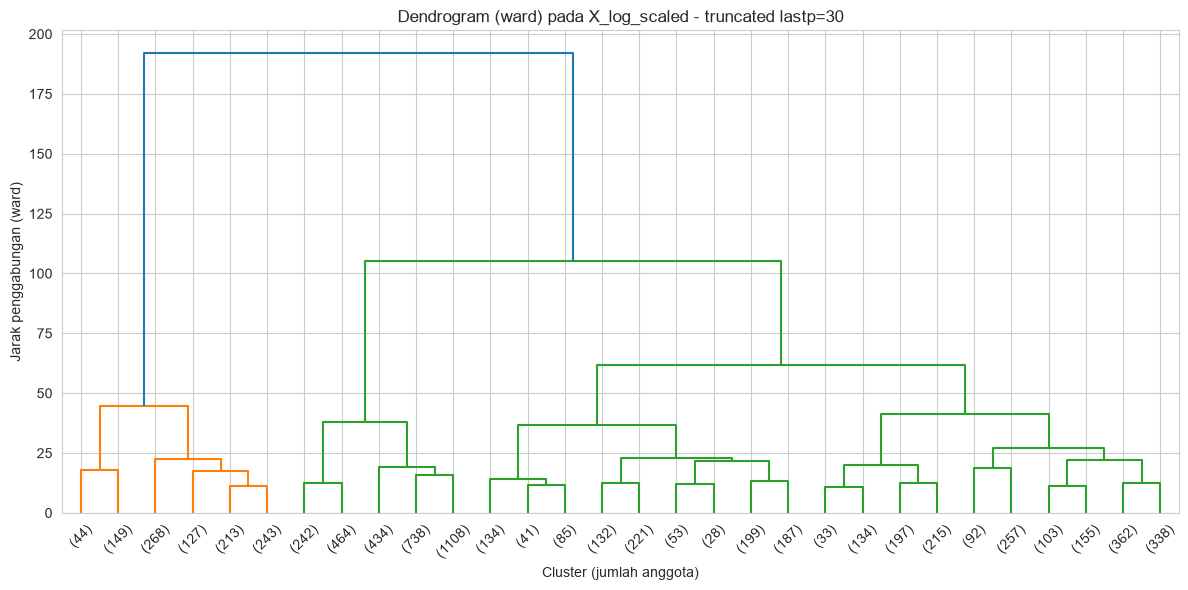

In [20]:
# Cell 2 (4.1): Tampilkan dendrogram (di-truncate agar mudah dibaca)

from scipy.cluster.hierarchy import dendrogram

plt.figure(figsize=(12, 6))
dendrogram(Z_ward, truncate_mode='lastp', p=30, show_leaf_counts=True)
plt.title('Dendrogram (ward) pada X_log_scaled - truncated lastp=30')
plt.xlabel('Cluster (jumlah anggota)')
plt.ylabel('Jarak penggabungan (ward)')
plt.grid(True)
plt.tight_layout()
plt.show()

## 4.2 Perbandingan Metode Linkage

Linkage menentukan cara jarak antar cluster dihitung. Pada bagian ini kalian akan membandingkan empat metode linkage: ward, complete, average, dan single.

In [21]:
# Cell 1 (4.2): Latih AgglomerativeClustering dengan ward, complete, average, single

from sklearn.cluster import AgglomerativeClustering

K_HC = K_FINAL  # samakan dengan K-Means final agar adil

linkage_list = ['ward', 'complete', 'average', 'single']
labels_hc = {}

for lk in linkage_list:
    agg = AgglomerativeClustering(n_clusters=K_HC, linkage=lk)
    labels_hc[lk] = agg.fit_predict(X_log_scaled)
    print(f"Linkage {lk} selesai. Ukuran cluster:",
          pd.Series(labels_hc[lk]).value_counts().sort_index().tolist())

Linkage ward selesai. Ukuran cluster: [2966, 1044, 2986]
Linkage complete selesai. Ukuran cluster: [1246, 347, 5403]
Linkage average selesai. Ukuran cluster: [5892, 1075, 29]
Linkage single selesai. Ukuran cluster: [6994, 1, 1]


,linkage,ukuran_cluster,min_size,max_size,rasio_max_min,silhouette
2,average,"[5892, 1075, 29]",29,5892,203.17,0.57
1,complete,"[1246, 347, 5403]",347,5403,15.57,0.48
0,ward,"[2966, 1044, 2986]",1044,2986,2.86,0.38
3,single,"[6994, 1, 1]",1,6994,"6,994.00",0.35


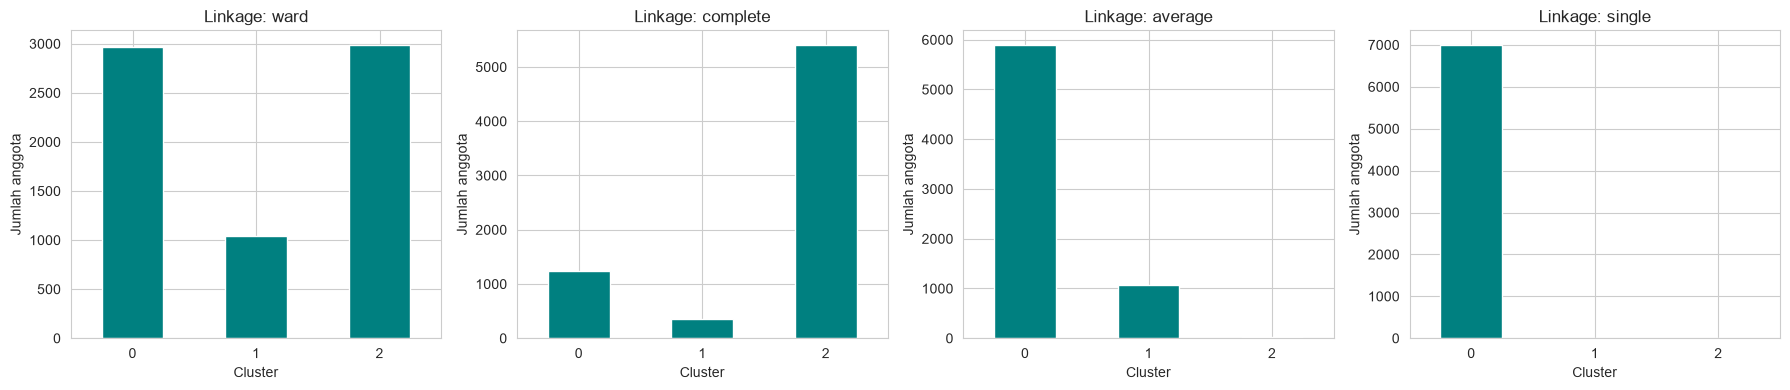

In [22]:
# Cell 2 (4.2): Bandingkan silhouette & ukuran cluster tiap linkage

hasil_42 = []
for lk, lab in labels_hc.items():
    sizes = pd.Series(lab).value_counts().sort_index()
    sil = silhouette_score(X_log_scaled, lab)
    hasil_42.append({
        'linkage': lk,
        'ukuran_cluster': sizes.tolist(),
        'min_size': sizes.min(),
        'max_size': sizes.max(),
        'rasio_max_min': round(sizes.max() / max(sizes.min(), 1), 2),
        'silhouette': round(sil, 4)
    })

df_hasil_42 = pd.DataFrame(hasil_42).sort_values('silhouette', ascending=False)
display(df_hasil_42)

# Visualisasi ukuran cluster per linkage
fig, axes = plt.subplots(1, 4, figsize=(18, 4))
for ax, (lk, lab) in zip(axes, labels_hc.items()):
    pd.Series(lab).value_counts().sort_index().plot(
        kind='bar', ax=ax, color='teal'
    )
    ax.set_title(f'Linkage: {lk}')
    ax.set_xlabel('Cluster')
    ax.set_ylabel('Jumlah anggota')
    ax.tick_params(axis='x', rotation=0)
plt.tight_layout()
plt.show()

**Pilihan linkage untuk Hierarchical Clustering:** ward

Alasannya ward meminimalkan kenaikan total within-cluster variance setiap kali menggabungkan cluster, sehingga cenderung menghasilkan cluster yang kompak dan seimbang pada data berdimensi rendah yang sudah di-scale.

## 4.3 Model Hierarchical Clustering Final

In [23]:
# Cell 1 (4.3): Latih AgglomerativeClustering final dengan linkage terbaik

agg_final = AgglomerativeClustering(n_clusters=K_FINAL, linkage='ward')
labels_hc_final = agg_final.fit_predict(X_log_scaled)

df['cluster_hc'] = labels_hc_final

sil_hc = silhouette_score(X_log_scaled, labels_hc_final)
print("Hierarchical final dilatih (ward, k =", K_FINAL, ")")
print("Silhouette Score:", round(sil_hc, 4))
print("\nJumlah anggota per cluster:")
print(pd.Series(labels_hc_final).value_counts().sort_index())

Hierarchical final dilatih (ward, k = 3 )
Silhouette Score: 0.3757

Jumlah anggota per cluster:
0    2966
1    1044
2    2986
Name: count, dtype: int64


Profil cluster HC (MEDIAN) pada data asli:


,num_likes,num_loves,num_other_reactions,num_comments,num_shares,jumlah_anggota
cluster_hc,,,,,,
0,147.00,1.00,0.00,9.00,1.00,2966
1,166.50,55.00,4.00,809.50,192.50,1044
2,14.00,0.00,0.00,0.00,0.00,2986



Profil cluster HC (MEAN) pada data asli:


,num_likes,num_loves,num_other_reactions,num_comments,num_shares
cluster_hc,,,,,
0,380.43,2.70,1.76,27.94,5.16
1,277.42,77.58,10.38,"1,427.88",254.45
2,17.22,0.09,0.00,1.69,0.27


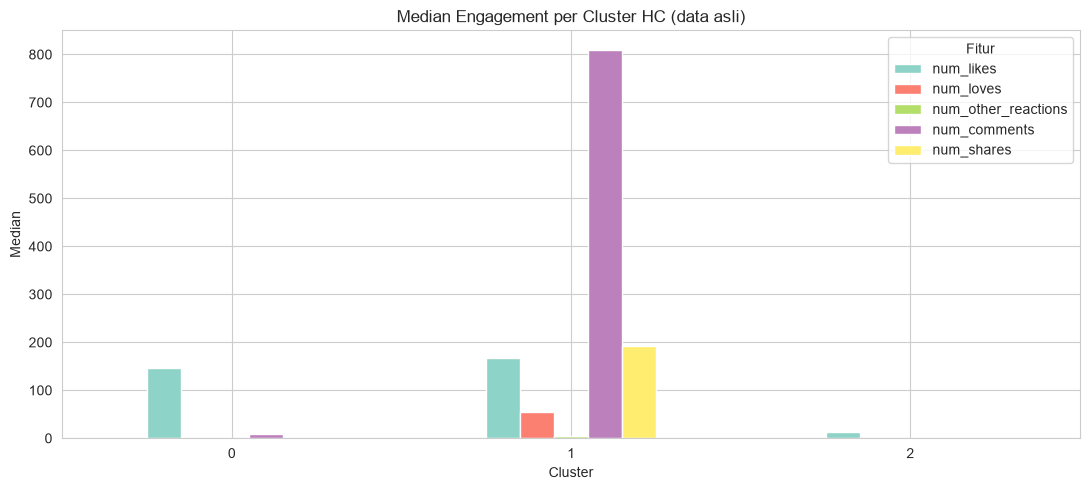

In [24]:
# Cell 2 (4.3): Profil cluster HC pada data asli (median & mean) + jumlah anggota

fitur_profil = ['num_likes', 'num_loves', 'num_other_reactions',
                'num_comments', 'num_shares']

profil_hc_median = df.groupby('cluster_hc')[fitur_profil].median()
profil_hc_median['jumlah_anggota'] = df.groupby('cluster_hc').size()

profil_hc_mean = df.groupby('cluster_hc')[fitur_profil].mean()

print("Profil cluster HC (MEDIAN) pada data asli:")
display(profil_hc_median)

print("\nProfil cluster HC (MEAN) pada data asli:")
display(profil_hc_mean)

profil_hc_median[fitur_profil].plot(
    kind='bar', figsize=(11, 5), colormap='Set3'
)
plt.title('Median Engagement per Cluster HC (data asli)')
plt.xlabel('Cluster')
plt.ylabel('Median')
plt.xticks(rotation=0)
plt.legend(title='Fitur')
plt.tight_layout()
plt.show()

# 5. Evaluasi Model

In [25]:
# Cell 1: Metrik evaluasi internal K-Means vs Hierarchical Clustering

from sklearn.metrics import (silhouette_score,
                             davies_bouldin_score,
                             calinski_harabasz_score)

def evaluasi_internal(X, labels, nama):
    return {
        'model': nama,
        'silhouette': round(silhouette_score(X, labels), 4),
        'davies_bouldin': round(davies_bouldin_score(X, labels), 4),
        'calinski_harabasz': round(calinski_harabasz_score(X, labels), 4)
    }

eval_km = evaluasi_internal(X_log_scaled, labels_km, 'K-Means')
eval_hc = evaluasi_internal(X_log_scaled, labels_hc_final, 'Hierarchical (ward)')

df_eval = pd.DataFrame([eval_km, eval_hc])
print("Perbandingan metrik evaluasi internal (pada X_log_scaled):")
display(df_eval.set_index('model'))

Perbandingan metrik evaluasi internal (pada X_log_scaled):


,silhouette,davies_bouldin,calinski_harabasz
model,,,
K-Means,0.43,0.95,"8,560.49"
Hierarchical (ward),0.38,0.95,"7,591.12"


Varians yang dijelaskan PC1: 73.14%
Varians yang dijelaskan PC2: 13.33%
Total 2 komponen: 86.47%


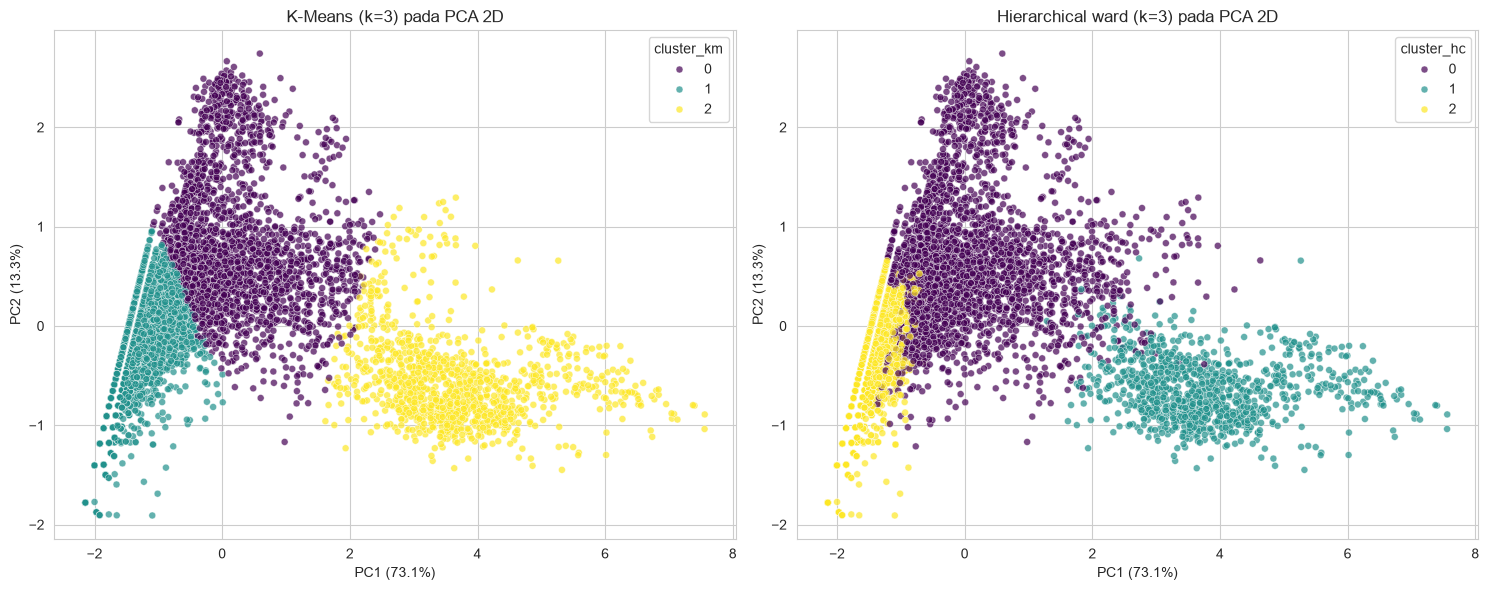

In [26]:
# Cell 2: PCA ke 2 komponen, scatter plot K-Means vs Hierarchical

from sklearn.decomposition import PCA

pca = PCA(n_components=2, random_state=RANDOM_STATE)
X_pca = pca.fit_transform(X_log_scaled)

var_explained = pca.explained_variance_ratio_
print("Varians yang dijelaskan PC1: {:.2%}".format(var_explained[0]))
print("Varians yang dijelaskan PC2: {:.2%}".format(var_explained[1]))
print("Total 2 komponen: {:.2%}".format(var_explained.sum()))

df_pca = pd.DataFrame(X_pca, columns=['PC1', 'PC2'])
df_pca['cluster_km'] = labels_km
df_pca['cluster_hc'] = labels_hc_final

fig, axes = plt.subplots(1, 2, figsize=(15, 6))

sns.scatterplot(data=df_pca, x='PC1', y='PC2', hue='cluster_km',
                palette='viridis', ax=axes[0], s=25, alpha=0.7)
axes[0].set_title('K-Means (k={}) pada PCA 2D'.format(K_FINAL))
axes[0].set_xlabel('PC1 ({:.1%})'.format(var_explained[0]))
axes[0].set_ylabel('PC2 ({:.1%})'.format(var_explained[1]))

sns.scatterplot(data=df_pca, x='PC1', y='PC2', hue='cluster_hc',
                palette='viridis', ax=axes[1], s=25, alpha=0.7)
axes[1].set_title('Hierarchical ward (k={}) pada PCA 2D'.format(K_FINAL))
axes[1].set_xlabel('PC1 ({:.1%})'.format(var_explained[0]))
axes[1].set_ylabel('PC2 ({:.1%})'.format(var_explained[1]))

plt.tight_layout()
plt.show()

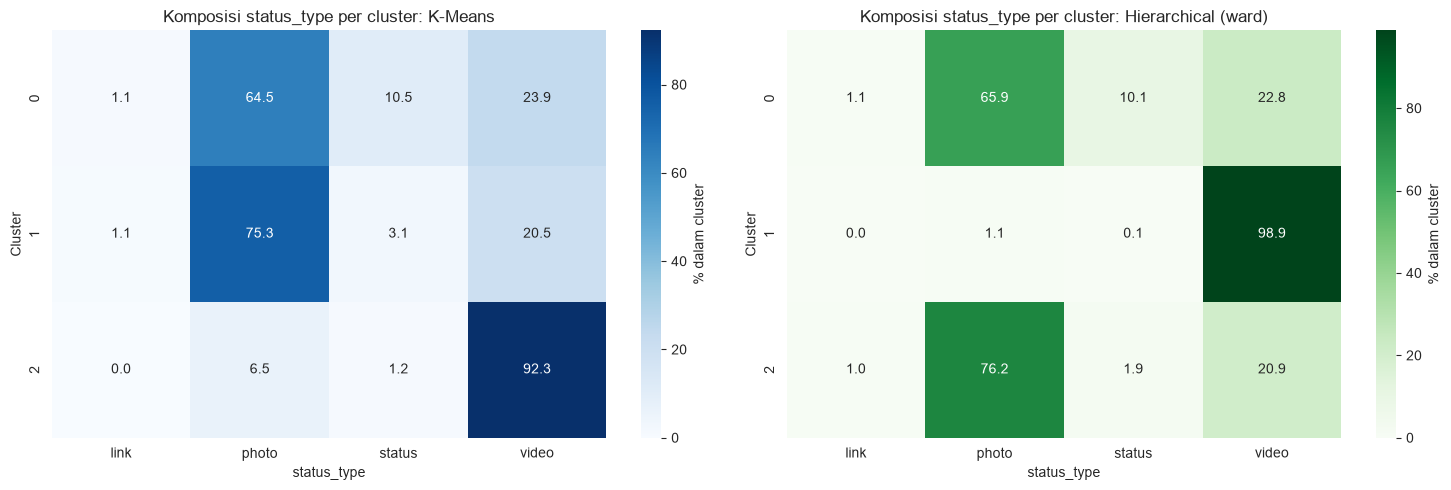

Crosstab % status_type - K-Means:


status_type,link,photo,status,video
cluster_km,,,,
0,1.09,64.50,10.50,23.91
1,1.07,75.35,3.13,20.46
2,0.00,6.53,1.22,92.25



Crosstab % status_type - Hierarchical:


status_type,link,photo,status,video
cluster_hc,,,,
0,1.15,65.91,10.11,22.83
1,0.00,1.05,0.10,98.85
2,0.97,76.22,1.94,20.86


In [27]:
# Cell 3: Komposisi status_type per cluster (crosstab %) untuk K-Means & HC

# Crosstab persen per baris (tiap baris = 1 cluster, jumlah = 100%)
ct_km = pd.crosstab(df['cluster_km'], df['status_type'], normalize='index') * 100
ct_hc = pd.crosstab(df['cluster_hc'], df['status_type'], normalize='index') * 100

fig, axes = plt.subplots(1, 2, figsize=(15, 5))

sns.heatmap(ct_km, annot=True, fmt='.1f', cmap='Blues',
            cbar_kws={'label': '% dalam cluster'}, ax=axes[0])
axes[0].set_title('Komposisi status_type per cluster: K-Means')
axes[0].set_xlabel('status_type')
axes[0].set_ylabel('Cluster')

sns.heatmap(ct_hc, annot=True, fmt='.1f', cmap='Greens',
            cbar_kws={'label': '% dalam cluster'}, ax=axes[1])
axes[1].set_title('Komposisi status_type per cluster: Hierarchical (ward)')
axes[1].set_xlabel('status_type')
axes[1].set_ylabel('Cluster')

plt.tight_layout()
plt.show()

print("Crosstab % status_type - K-Means:")
display(ct_km.round(2))
print("\nCrosstab % status_type - Hierarchical:")
display(ct_hc.round(2))

In [28]:
# Cell RINGKASAN: kumpulkan semua output yang diperlukan untuk analisis
# Jalankan cell ini setelah semua cell Langkah 1-5 dieksekusi.

import pandas as pd
import numpy as np
from sklearn.metrics import silhouette_score

pd.set_option('display.max_columns', None)
pd.set_option('display.width', 200)
pd.set_option('display.float_format', lambda x: f'{x:,.4f}')

def header(t):
    print("\n" + "#" * 70)
    print("#", t)
    print("#" * 70)

fitur_profil = ['num_likes', 'num_loves', 'num_other_reactions',
                'num_comments', 'num_shares']

# 1. Info dataset & missing/duplikat
header("1. DATASET & KUALITAS DATA")
print("Shape df setelah cleaning:", df.shape)
print("Jumlah kolom kosong yang tersisa:",
      df.columns[df.isna().all()].tolist())
print("Total missing value:", int(df.isna().sum().sum()))
print("Duplikat (tanpa status_id):",
      int(df.drop(columns=['status_id']).duplicated().sum()))

# 2. Skewness & proporsi nol fitur terpilih
header("2. SKEWNESS & PROPORSI NOL FITUR TERPILIH")
skew_tab = pd.DataFrame({
    'skew_raw': df[fitur_profil].skew(),
    'proporsi_nol': (df[fitur_profil] == 0).mean(),
    'skew_log1p': np.log1p(df[fitur_profil]).skew()
})
print(skew_tab)

# 3. Perbandingan 3.1 (log & scaling)
header("3. PENGARUH LOG & SCALING (3.1)")
print(df_hasil_31.to_string(index=False))

var_raw = X_raw.var().sort_values(ascending=False)
print("\nVarians X_raw (tanpa scaling):")
print(var_raw)
print("Rasio var max/min:", round(var_raw.max() / var_raw.min(), 2))

# 4. Elbow & silhouette
header("4. ELBOW & SILHOUETTE (3.2 & 3.3)")
elbow_df = pd.DataFrame({'k': list(range(2, 2 + len(inertias))),
                         'inertia': np.round(inertias, 4)})
elbow_df['delta_inertia'] = elbow_df['inertia'].diff().round(4)
print("Elbow:")
print(elbow_df.to_string(index=False))

sil_df = pd.DataFrame({'k': list(sil_scores.keys()),
                       'silhouette': [round(v, 4) for v in sil_scores.values()]})
print("\nSilhouette:")
print(sil_df.to_string(index=False))

# 5. K final & sil K-Means final
header("5. K-FINAL & HASIL K-MEANS FINAL (3.4)")
print("K_FINAL =", K_FINAL)
print("Inertia K-Means final:", round(km_final.inertia_, 4))
print("Silhouette K-Means final:", round(silhouette_score(X_log_scaled, labels_km), 4))
print("Ukuran cluster K-Means:",
      pd.Series(labels_km).value_counts().sort_index().to_dict())

print("\nProfil MEDIAN K-Means (data asli):")
profil_km = df.groupby('cluster_km')[fitur_profil].median()
profil_km['n'] = df.groupby('cluster_km').size()
print(profil_km)

print("\nProfil MEAN K-Means (data asli):")
print(df.groupby('cluster_km')[fitur_profil].mean())

# 6. Perbandingan linkage (4.2)
header("6. PERBANDINGAN LINKAGE (4.2)")
print(df_hasil_42.to_string(index=False))

# 7. Hasil HC final (4.3)
header("7. HC FINAL (4.3)")
print("Silhouette HC final:", round(silhouette_score(X_log_scaled, labels_hc_final), 4))
print("Ukuran cluster HC:",
      pd.Series(labels_hc_final).value_counts().sort_index().to_dict())

print("\nProfil MEDIAN HC (data asli):")
profil_hc = df.groupby('cluster_hc')[fitur_profil].median()
profil_hc['n'] = df.groupby('cluster_hc').size()
print(profil_hc)

print("\nProfil MEAN HC (data asli):")
print(df.groupby('cluster_hc')[fitur_profil].mean())

# 8. Evaluasi internal (5)
header("8. EVALUASI INTERNAL (5)")
print(df_eval.set_index('model').to_string())

# 9. PCA variance
header("9. PCA VARIANCE")
print("PC1:", round(float(var_explained[0]), 4))
print("PC2:", round(float(var_explained[1]), 4))
print("Total:", round(float(var_explained.sum()), 4))

# 10. Crosstab status_type per cluster
header("10. KOMPOSISI status_type PER CLUSTER (%)")
print("K-Means:")
print(ct_km.round(2))
print("\nHierarchical:")
print(ct_hc.round(2))

# 11. Kesamaan partisi K-Means vs HC
header("11. KESAMAAN PARTISI K-MEANS vs HC")
from sklearn.metrics import adjusted_rand_score, normalized_mutual_info_score
print("Adjusted Rand Index:", round(adjusted_rand_score(labels_km, labels_hc_final), 4))
print("Normalized Mutual Info:", round(normalized_mutual_info_score(labels_km, labels_hc_final), 4))

# 12. Ringkasan dendrogram (jarak merge teratas)
header("12. JARAK MERGE TERATAS PADA LINKAGE WARD")
merge_df = pd.DataFrame(Z_ward[:, [0, 1, 2, 3]],
                        columns=['a', 'b', 'jarak', 'n'])
print("Top 10 merge terakhir (jarak terjauh):")
print(merge_df.tail(10).to_string(index=False))
print("\nJarak merge 5 terakhir (lompatan):")
d = merge_df['jarak'].values
print(pd.DataFrame({
    'merge_ke': range(len(d)-5, len(d)),
    'jarak': d[-5:],
    'delta': np.diff(d)[-5:] if len(d) > 1 else []
}).to_string(index=False))


######################################################################
# 1. DATASET & KUALITAS DATA
######################################################################
Shape df setelah cleaning: (6996, 17)
Jumlah kolom kosong yang tersisa: []
Total missing value: 0
Duplikat (tanpa status_id): 0

######################################################################
# 2. SKEWNESS & PROPORSI NOL FITUR TERPILIH
######################################################################
                     skew_raw  proporsi_nol  skew_log1p
num_likes              3.9325        0.0176     -0.0122
num_loves              5.9850        0.6039      1.5181
num_other_reactions   13.9940        0.6894      1.9780
num_comments           8.9942        0.3025      1.0477
num_shares             7.0720        0.5582      1.5291

######################################################################
# 3. PENGARUH LOG & SCALING (3.1)
######################################################################


# 6. Analisis

# Analisis Hasil Eksperimen

## 1. Pengaruh Transformasi Log dan Feature Scaling

Perbandingan tiga versi data dengan k=3 menunjukkan perbedaan yang jelas:

| Versi data | Ukuran cluster | Silhouette |
|---|---|---|
| X_raw | [6392, 137, 467] | 0.2982 |
| X_raw_scaled | [292, 6331, 373] | 0.2416 |
| X_log_scaled | [2200, 3647, 1149] | **0.4325** |

Pada data mentah, `num_comments` dan `num_likes` punya varians ratusan ribu, sedangkan `num_other_reactions` hanya sekitar 122 (rasio ~6.500×). Akibatnya K-Means hanya "melihat" dua fitur itu dan menghasilkan satu cluster raksasa berisi 6.392 titik. Scaling saja tidak cukup: karena distribusinya sangat miring (skewness sampai 13.99), outlier ekstrem masih menarik centroid, sehingga silhouette justru paling rendah. Setelah log1p, skewness turun drastis (misal `num_likes` dari 3.93 ke -0.01), lalu scaling menyeimbangkan skala. Hasilnya cluster paling seimbang dan silhouette tertinggi (0.4325). Jadi log dan scaling **saling melengkapi**: log meredam outlier, scaling menyetarakan skala.

## 2. Penanganan Kolom Redundan dan Sparse

`num_reactions` dibuang karena merupakan penjumlahan semua reaksi emoji (redundan) dan sangat berkorelasi dengan `num_likes` — kalau dipakai, informasinya dihitung dua kali dalam jarak. Emoji yang jarang muncul (`num_wows`, `num_hahas`, `num_sads`, `num_angrys`) digabung menjadi `num_other_reactions` karena mayoritas bernilai nol dan maknanya mirip. Fitur final: `num_likes`, `num_loves`, `num_other_reactions`, `num_comments`, `num_shares`.

## 3. Jumlah Cluster Optimal

Elbow Method menunjukkan siku di **k=3** (delta inertia melompat dari -4.931 ke -1.695). Silhouette tertinggi justru di **k=2** (0.5871), tapi k=3 masih wajar (0.4325). Saya pilih **k=3** karena k=2 hanya memisahkan "rendah vs tinggi" dan menggabungkan dua kelompok yang profilnya sangat berbeda. k=3 juga menghasilkan cluster seimbang dan mudah diinterpretasi.

## 4. Perbandingan Linkage

| Linkage | Ukuran cluster | Silhouette |
|---|---|---|
| average | [5892, 1075, 29] | 0.5726 |
| complete | [1246, 347, 5403] | 0.4784 |
| **ward** | [2966, 1044, 2986] | 0.3757 |
| single | [6994, 1, 1] | 0.3526 |

`single` gagal karena **chaining** — satu cluster berisi hampir semua data (6.994 titik) dan dua cluster hanya 1 titik (outlier ekstrem). `average` punya silhouette tertinggi tapi cluster 29 titiknya sulit diinterpretasi. Saya pilih **ward** karena clusternya paling seimbang (rasio max/min 2.86) dan konsepnya mirip K-Means (sama-sama meminimalkan within-cluster variance).

## 5. K-Means vs Hierarchical

| Model | Silhouette ↑ | Davies-Bouldin ↓ | Calinski-Harabasz ↑ |
|---|---|---|---|
| K-Means | **0.4325** | 0.9541 | **8.560** |
| Hierarchical (ward) | 0.3757 | **0.9476** | 7.591 |

K-Means sedikit lebih baik di silhouette dan Calinski-Harabasz, HC sedikit lebih baik di Davies-Bouldin (selisih sangat kecil). **ARI = 0.669** dan **NMI = 0.706**, artinya kedua partisi sepakat pada ~70% penataan titik. PCA 2D (86.47% varians) juga menunjukkan pola pemisahan yang hampir identik. Jadi hasilnya **tidak berbeda signifikan** — wajar karena ward dan K-Means punya objective yang mirip dan `k`-nya sama.

## 6. Karakteristik Tiap Cluster

| Cluster | Median (likes / comments / shares) | Dominasi status_type | Julukan |
|---|---|---|---|
| 0 (2.200) | 204 / 11 / 1 | 64.5% photo | **Populer tapi Pasif** |
| 1 (3.647) | 18 / 0 / 0 | 75.4% photo | **Posting Sepi** |
| 2 (1.149) | 177 / 703 / 174 | **92.3% video** | **Viral Berbasis Video** |

Insight paling menarik: Cluster 0 dan Cluster 2 punya like yang mirip (204 vs 177), tapi komentar dan share Cluster 2 jauh lebih tinggi (703 vs 11, 174 vs 1). Dan Cluster 2 hampir seluruhnya video. Artinya **video adalah pemicu diskusi dan penyebaran**, bukan sekadar like.

## 7. Kelebihan dan Kekurangan

**K-Means**
- Kelebihan: cepat, hemat memori, skalabel, centroid langsung bisa diinterpretasi, ada refinement iteratif.
- Kekurangan: harus tentukan k di awal, asumsi cluster bulat, sensitif outlier dan skala.

**Hierarchical (Agglomerative)**
- Kelebihan: tidak perlu tentukan k di awal (bisa lihat dendrogram dulu), dendrogram informatif, fleksibel lewat linkage, deterministik.
- Kekurangan: kompleksitas O(n² log n) — tidak skalabel untuk data besar, tidak ada refinement, hasil sangat tergantung linkage.

Untuk dataset ini keduanya setara. Untuk data yang lebih besar, K-Means lebih praktis.



# 7. Kesimpulan dan Saran

## Kesimpulan

1. **Log + scaling wajib** pada data engagement yang sangat miring. Log meredam outlier, scaling menyetarakan skala. Tanpa keduanya, K-Means hanya "melihat" dua fitur bervarians besar.
2. **Pemilihan fitur penting**: `num_reactions` dibuang karena redundan, emoji sparse digabung untuk mengurangi noise.
3. **k=3 dipilih** karena elbow tegas di k=3 dan k=2 terlalu kasar (hanya misahkan rendah vs tinggi).
4. **Ward linkage terbaik** — cluster seimbang dan konsisten dengan K-Means. Single linkage gagal karena chaining.
5. **K-Means dan HC hasilnya setara** (ARI 0.669), karena objective-nya mirip dan k-nya sama.
6. **Tiga segmen bermakna**: "Posting Sepi", "Populer tapi Pasif", dan "Viral Berbasis Video". Insight bisnis utamanya: **video memicu komentar dan share**, bukan sekadar like.

## Saran

1. **Clustering terpisah per periode** (misal sebelum vs sesudah 2016) untuk melihat apakah pola engagement berubah seiring waktu.
2. **Manfaatkan fitur waktu** seperti jam dan hari posting — mungkin posting di jam tertentu lebih sering masuk cluster viral.
3. **Coba algoritma lain**: DBSCAN (untuk deteksi outlier eksplisit), GMM (untuk soft assignment), atau HDBSCAN.
4. **Reduksi dimensi sebelum clustering** dengan PCA (2–3 komponen) dan bandingkan hasilnya — kalau setara, pipeline bisa lebih cepat.
5. **Tuning hyperparameter**: coba `init`, `n_init`, dan linkage lain (`centroid`, `median`). Cek stabilitas cluster dengan beberapa seed.
6. **Validasi eksternal** menggunakan `status_type` sebagai label proxy, dan profiling cluster lebih dalam (waktu posting, panjang caption, dsb).